In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
import keras
from keras import layers, models, callbacks
from keras.utils import to_categorical
from sklearn.model_selection import KFold

np.random.seed(42)
tf.random.set_seed(42)

os.makedirs('models', exist_ok=True)
os.makedirs('my_digits', exist_ok=True)

print(f"Версія TensorFlow: {tf.__version__}")
print(f"Версія Keras: {keras.__version__}")


Версія TensorFlow: 2.21.0
Версія Keras: 3.15.1


In [ ]:
(x_train_t1, y_train_t1), (x_test_t1, y_test_t1) = keras.datasets.mnist.load_data()
x_train_t1 = x_train_t1.astype('float32') / 255.0
x_test_t1 = x_test_t1.astype('float32') / 255.0

class myCallback(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        current_acc = logs.get('accuracy')
        if current_acc is not None and current_acc >= 0.99:
            print("\nДосягнуто 99% точності, тому скасовуємо навчання!")
            self.model.stop_training = True

callback_t1 = myCallback()

model_t1 = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_t1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print(model_t1.summary())

history_t1 = model_t1.fit(
    x_train_t1, 
    y_train_t1, 
    epochs=9, 
    batch_size=128,
    callbacks=[callback_t1],
    verbose=1
)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_10 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/9
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9244 - loss: 0.2663
Epoch 2/9
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9689 - loss: 0.1077
Epoch 3/9
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9802 - loss: 0.0691
Epoch 4/9
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9865 - loss: 0.0476
Epoch 5/9
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9915 - loss: 0.0332
Досягнуто 99% точності, тому скасовуємо навчання!
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9915 - loss: 0.0332


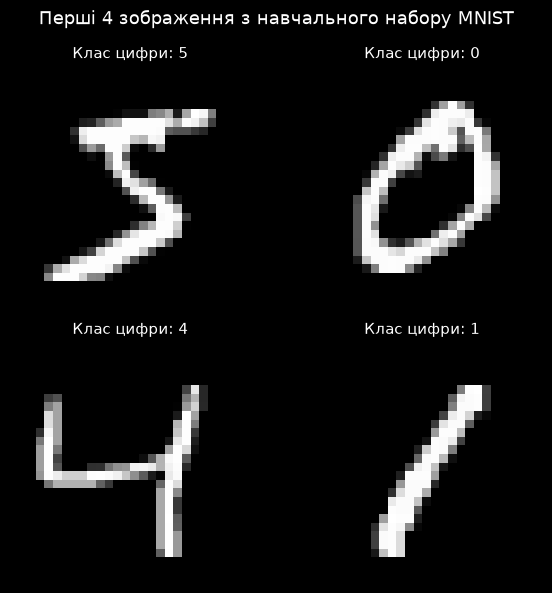

In [ ]:
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.mnist.load_data()

plt.figure(figsize=(6, 6))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(X_train_raw[i], cmap='gray')
    plt.title(f"Клас цифри: {y_train_raw[i]}", fontsize=11)
    plt.axis('off')
plt.suptitle("Перші 4 зображення з навчального набору MNIST", fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
num_pixels = 28 * 28
X_train_mlp = X_train_raw.reshape((X_train_raw.shape[0], num_pixels)).astype('float32') / 255.0
X_test_mlp = X_test_raw.reshape((X_test_raw.shape[0], num_pixels)).astype('float32') / 255.0

y_train_cat = to_categorical(y_train_raw, num_classes=10)
y_test_cat = to_categorical(y_test_raw, num_classes=10)

print(f"Форма X_train_mlp: {X_train_mlp.shape}")
print(f"Форма y_train_cat: {y_train_cat.shape}")
print(f"Форма X_test_mlp: {X_test_mlp.shape}")


Форма X_train_mlp: (60000, 784)
Форма y_train_cat: (60000, 10)
Форма X_test_mlp: (10000, 784)


In [ ]:
def baseline_mlp_model():
    model = models.Sequential([
        layers.Input(shape=(num_pixels,)),
        layers.Dense(num_pixels, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )
    return model

model_mlp = baseline_mlp_model()
model_mlp.summary()


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_30 (Dense)                │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,290 (2.38 MB)

 Trainable params: 623,290 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_mlp = model_mlp.fit(
    X_train_mlp, 
    y_train_cat, 
    validation_data=(X_test_mlp, y_test_cat), 
    epochs=10, 
    batch_size=200, 
    verbose=1
)

scores_mlp = model_mlp.evaluate(X_test_mlp, y_test_cat, verbose=0)
mlp_accuracy = scores_mlp[1] * 100
mlp_error = 100 - mlp_accuracy

print(f"\nТочність MLP на тестовому наборі: {mlp_accuracy:.2f}%")
print(f"Показник помилки класифікації MLP: {mlp_error:.2f}%")

mlp_path = 'models/mlp_mnist.keras'
model_mlp.save(mlp_path)
print(f"Модель MLP збережено у файл: {mlp_path}")


Epoch 1/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9219 - loss: 0.2754 - val_accuracy: 0.9607 - val_loss: 0.1363
Epoch 2/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9679 - loss: 0.1118 - val_accuracy: 0.9697 - val_loss: 0.0994
Epoch 3/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9796 - loss: 0.0714 - val_accuracy: 0.9735 - val_loss: 0.0837
Epoch 4/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9863 - loss: 0.0493 - val_accuracy: 0.9760 - val_loss: 0.0763
Epoch 5/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9910 - loss: 0.0353 - val_accuracy: 0.9779 - val_loss: 0.0701
Epoch 6/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9943 - loss: 0.0256 - val_accuracy: 0.9800 - val_loss: 0.0647
Epoch 7/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9965 - loss: 0.0189 - val_accuracy: 0.9805 - val_loss: 0.0611
Epoch 8/10
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9976 - loss: 0.0142 - val_accuracy: 0.

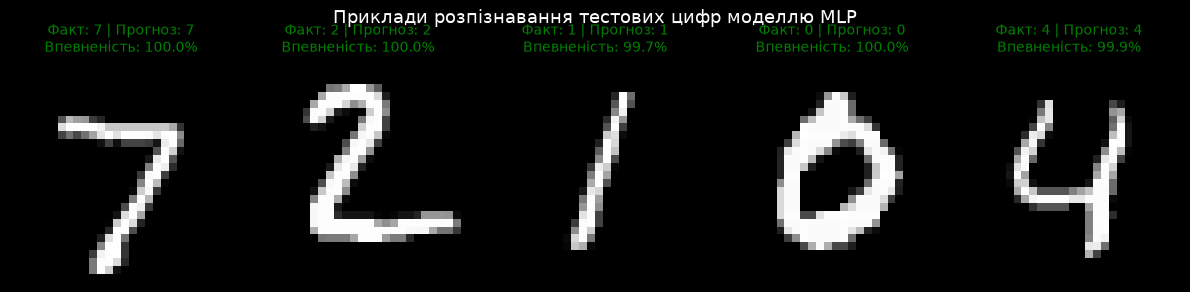

In [ ]:
sample_indices = [0, 1, 2, 3, 4]
sample_images = X_test_mlp[sample_indices]
predictions_mlp = model_mlp.predict(sample_images, verbose=0)

plt.figure(figsize=(12, 3))
for i, idx in enumerate(sample_indices):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test_raw[idx], cmap='gray')
    pred_label = np.argmax(predictions_mlp[i])
    true_label = y_test_raw[idx]
    conf = np.max(predictions_mlp[i]) * 100
    color = 'green' if pred_label == true_label else 'red'
    plt.title(f"Факт: {true_label} | Прогноз: {pred_label}\nВпевненість: {conf:.1f}%", color=color, fontsize=10)
    plt.axis('off')
plt.suptitle("Приклади розпізнавання тестових цифр моделлю MLP", fontsize=13)
plt.tight_layout()
plt.show()


In [ ]:
x_train_cnn1 = x_train_t1.reshape((-1, 28, 28, 1))
x_test_cnn1 = x_test_t1.reshape((-1, 28, 28, 1))

class ConvCallback(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        current_acc = logs.get('accuracy')
        if current_acc is not None and current_acc >= 0.995:
            print("\nДосягнуто 99,5% точності, тому навчання скасовується!")
            self.model.stop_training = True

callback_cnn1 = ConvCallback()

model_cnn1 = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_cnn1.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn1.summary()

history_cnn1 = model_cnn1.fit(
    x_train_cnn1, 
    y_train_t1, 
    epochs=10, 
    batch_size=128,
    callbacks=[callback_cnn1],
    verbose=1
)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9412 - loss: 0.2102
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9813 - loss: 0.0646
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9873 - loss: 0.0439
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9912 - loss: 0.0319
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9940 - loss: 0.0232
Epoch 6/10
468/469 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9960 - loss: 0.0165
Досягнуто 99,5% точності, тому навчання скасовується!
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9960 - loss: 0.0165


In [ ]:
X_train_cnn = X_train_raw.reshape((X_train_raw.shape[0], 28, 28, 1)).astype('float32') / 255.0
X_test_cnn = X_test_raw.reshape((X_test_raw.shape[0], 28, 28, 1)).astype('float32') / 255.0

def build_simple_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (5, 5), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )
    return model

model_simple_cnn = build_simple_cnn()
model_simple_cnn.summary()

history_simple_cnn = model_simple_cnn.fit(
    X_train_cnn, 
    y_train_cat, 
    validation_data=(X_test_cnn, y_test_cat), 
    epochs=5, 
    batch_size=200, 
    verbose=1
)

scores_simple = model_simple_cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"\nТочність Simple CNN на тесті: {scores_simple[1]*100:.2f}% (Помилка: {100 - scores_simple[1]*100:.2f}%)")


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_19 (Conv2D)              │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 592,074 (2.26 MB)

 Trainable params: 592,074 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9271 - loss: 0.2501 - val_accuracy: 0.9750 - val_loss: 0.0803
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9786 - loss: 0.0743 - val_accuracy: 0.9812 - val_loss: 0.0540
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9837 - loss: 0.0545 - val_accuracy: 0.9840 - val_loss: 0.0483
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9870 - loss: 0.0422 - val_accuracy: 0.9870 - val_loss: 0.0406
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.9892 - loss: 0.0348 - val_accuracy: 0.9882 - val_loss: 0.0362

Точність Simple CNN на тесті: 98.82% (Помилка: 1.18%)


In [ ]:
def build_deeper_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(30, (5, 5), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(15, (3, 3), activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(50, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )
    return model

model_deeper_cnn = build_deeper_cnn()
model_deeper_cnn.summary()

history_deeper_cnn = model_deeper_cnn.fit(
    X_train_cnn, 
    y_train_cat, 
    validation_data=(X_test_cnn, y_test_cat), 
    epochs=5, 
    batch_size=200, 
    verbose=1
)

scores_deeper = model_deeper_cnn.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"\nТочність Deeper CNN на тесті: {scores_deeper[1]*100:.2f}% (Помилка: {100 - scores_deeper[1]*100:.2f}%)")


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_20 (Conv2D)              │ (None, 24, 24, 30)     │           780 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 12, 12, 30)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 10, 10, 15)     │         4,065 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 5, 5, 15)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 5, 5, 15)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_13 (Flatten)            │ (None, 375)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 128)            │        48,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 50)             │         6,450 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 10)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,933 (234.11 KB)

 Trainable params: 59,933 (234.11 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.8743 - loss: 0.3980 - val_accuracy: 0.9747 - val_loss: 0.0800
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.9713 - loss: 0.0943 - val_accuracy: 0.9842 - val_loss: 0.0488
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9789 - loss: 0.0668 - val_accuracy: 0.9877 - val_loss: 0.0388
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9826 - loss: 0.0560 - val_accuracy: 0.9893 - val_loss: 0.0333
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9854 - loss: 0.0482 - val_accuracy: 0.9902 - val_loss: 0.0291

Точність Deeper CNN на тесті: 99.02% (Помилка: 0.98%)


In [ ]:
print("Виконання 5-Fold Cross-Validation для оцінки стабільності архітектури...")
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

subset_size = 5000
X_sub = X_train_cnn[:subset_size]
y_sub = y_train_cat[:subset_size]

for fold, (train_idx, val_idx) in enumerate(kfold.split(X_sub, y_sub), 1):
    temp_model = build_deeper_cnn()
    temp_model.fit(
        X_sub[train_idx], y_sub[train_idx],
        epochs=2,
        batch_size=128,
        verbose=0
    )
    val_loss, val_acc = temp_model.evaluate(X_sub[val_idx], y_sub[val_idx], verbose=0)
    cv_scores.append(val_acc)
    print(f"  Fold {fold}: Точність = {val_acc*100:.2f}%")

print(f"\nСередня точність 5-Fold CV: {np.mean(cv_scores)*100:.2f}% (± {np.std(cv_scores)*100:.2f}%)")


Виконання 5-Fold Cross-Validation для оцінки стабільності архітектури...
  Fold 1: Точність = 89.30%
  Fold 2: Точність = 91.40%
  Fold 3: Точність = 88.80%
  Fold 4: Точність = 89.90%
  Fold 5: Точність = 90.40%

Середня точність 5-Fold CV: 89.96% (± 0.90%)


In [ ]:
def build_improved_cnn():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )
    return model

model_improved = build_improved_cnn()
model_improved.summary()

history_improved = model_improved.fit(
    X_train_cnn, 
    y_train_cat, 
    validation_data=(X_test_cnn, y_test_cat), 
    epochs=6, 
    batch_size=200, 
    verbose=1
)

scores_improved = model_improved.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"\nФінальна точність Improved CNN на тесті: {scores_improved[1]*100:.2f}% (Помилка: {100 - scores_improved[1]*100:.2f}%)")

best_model_path = 'models/cnn_mnist_best.keras'
model_improved.save(best_model_path)
print(f"Найкращу модель успішно збережено у: {best_model_path}")


Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_32 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_19 (Flatten)            │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,154 (1.61 MB)

 Trainable params: 421,898 (1.61 MB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.9342 - loss: 0.2168 - val_accuracy: 0.9856 - val_loss: 0.2013
Epoch 2/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9792 - loss: 0.0695 - val_accuracy: 0.9888 - val_loss: 0.0378
Epoch 3/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.9835 - loss: 0.0539 - val_accuracy: 0.9911 - val_loss: 0.0271
Epoch 4/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.9871 - loss: 0.0430 - val_accuracy: 0.9918 - val_loss: 0.0259
Epoch 5/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.9878 - loss: 0.0377 - val_accuracy: 0.9920 - val_loss: 0.0260
Epoch 6/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - accuracy: 0.9893 - loss: 0.0331 - val_accuracy: 0.9921 - val_loss: 0.0236

Фінальна точність Improved CNN на тесті: 99.21% (Помилка: 0.79%)
Найкращу модель успішно збережено у: models/cnn_mnist_best.keras


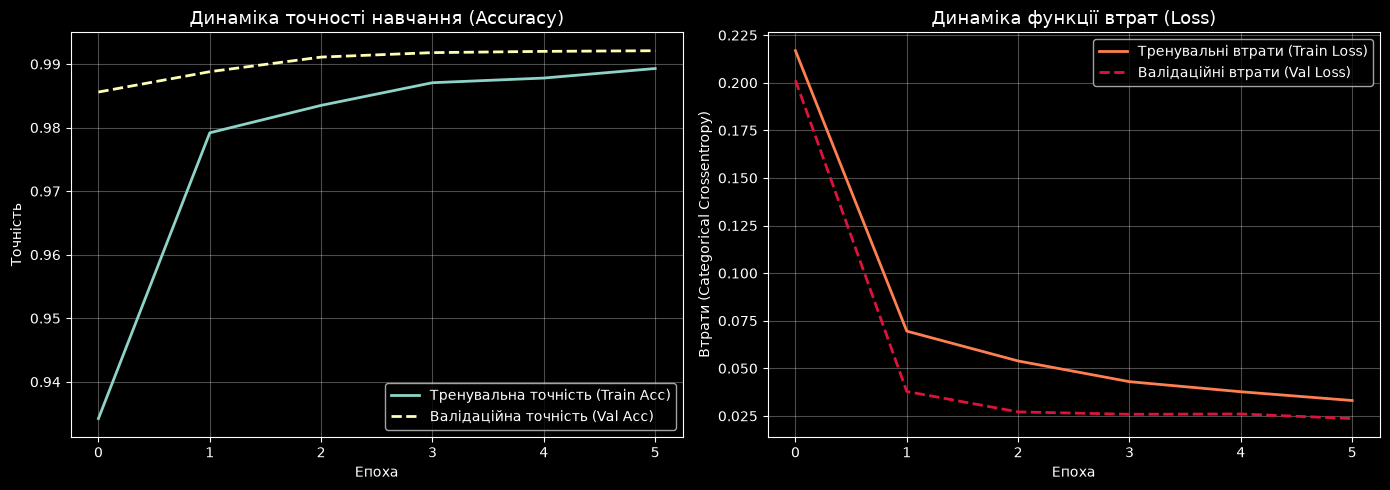

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_improved.history['accuracy'], label='Тренувальна точність (Train Acc)', lw=2)
plt.plot(history_improved.history['val_accuracy'], label='Валідаційна точність (Val Acc)', lw=2, linestyle='--')
plt.title('Динаміка точності навчання (Accuracy)', fontsize=13)
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_improved.history['loss'], label='Тренувальні втрати (Train Loss)', lw=2, color='coral')
plt.plot(history_improved.history['val_loss'], label='Валідаційні втрати (Val Loss)', lw=2, linestyle='--', color='crimson')
plt.title('Динаміка функції втрат (Loss)', fontsize=13)
plt.xlabel('Епоха')
plt.ylabel('Втрати (Categorical Crossentropy)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
loaded_model = keras.models.load_model('models/cnn_mnist_best.keras')
loaded_model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)
print("Збережену найкращу модель успішно завантажено та перекомпільовано!")

Збережену найкращу модель успішно завантажено та перекомпільовано!


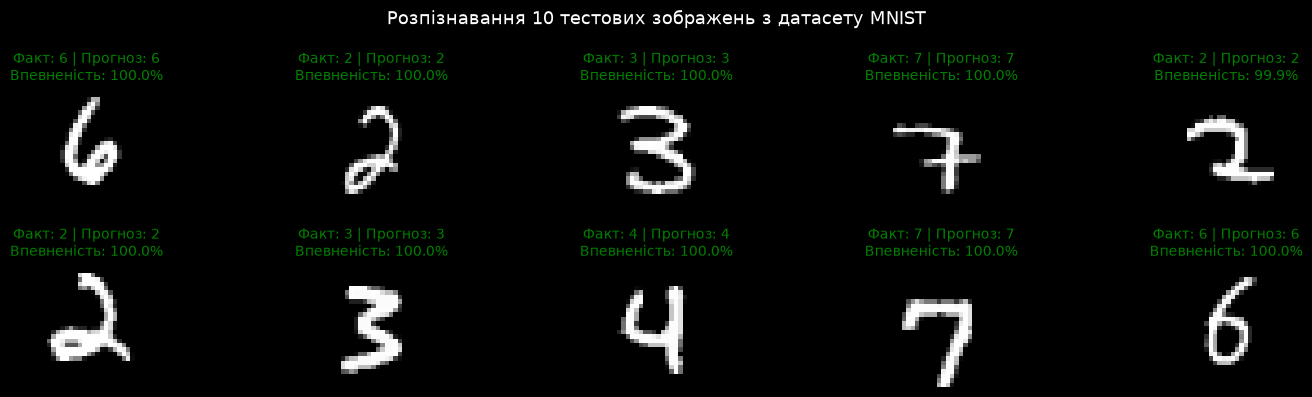

In [ ]:
test_indices = np.random.choice(len(X_test_raw), 10, replace=False)
mnist_samples = X_test_cnn[test_indices]
mnist_true_labels = y_test_raw[test_indices]

mnist_preds = loaded_model.predict(mnist_samples, verbose=0)
mnist_pred_labels = np.argmax(mnist_preds, axis=1)

plt.figure(figsize=(15, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test_raw[test_indices[i]], cmap='gray')
    conf = np.max(mnist_preds[i]) * 100
    is_correct = mnist_pred_labels[i] == mnist_true_labels[i]
    color = 'green' if is_correct else 'red'
    plt.title(f"Факт: {mnist_true_labels[i]} | Прогноз: {mnist_pred_labels[i]}\nВпевненість: {conf:.1f}%", color=color, fontsize=10)
    plt.axis('off')
plt.suptitle("Розпізнавання 10 тестових зображень з датасету MNIST", fontsize=13)
plt.tight_layout()
plt.show()


In [ ]:
def preprocess_custom_image(image_path):
    img = Image.open(image_path).convert('L')
    
    img_resized = img.resize((28, 28), Image.Resampling.LANCZOS)
    
    arr = np.array(img_resized, dtype=np.float32)
    
    arr_inverted = 255.0 - arr
    
    arr_normalized = arr_inverted / 255.0
    
    arr_normalized[arr_normalized < 0.15] = 0.0
    
    tensor_input = arr_normalized.reshape((1, 28, 28, 1))
    
    return img, arr_normalized, tensor_input


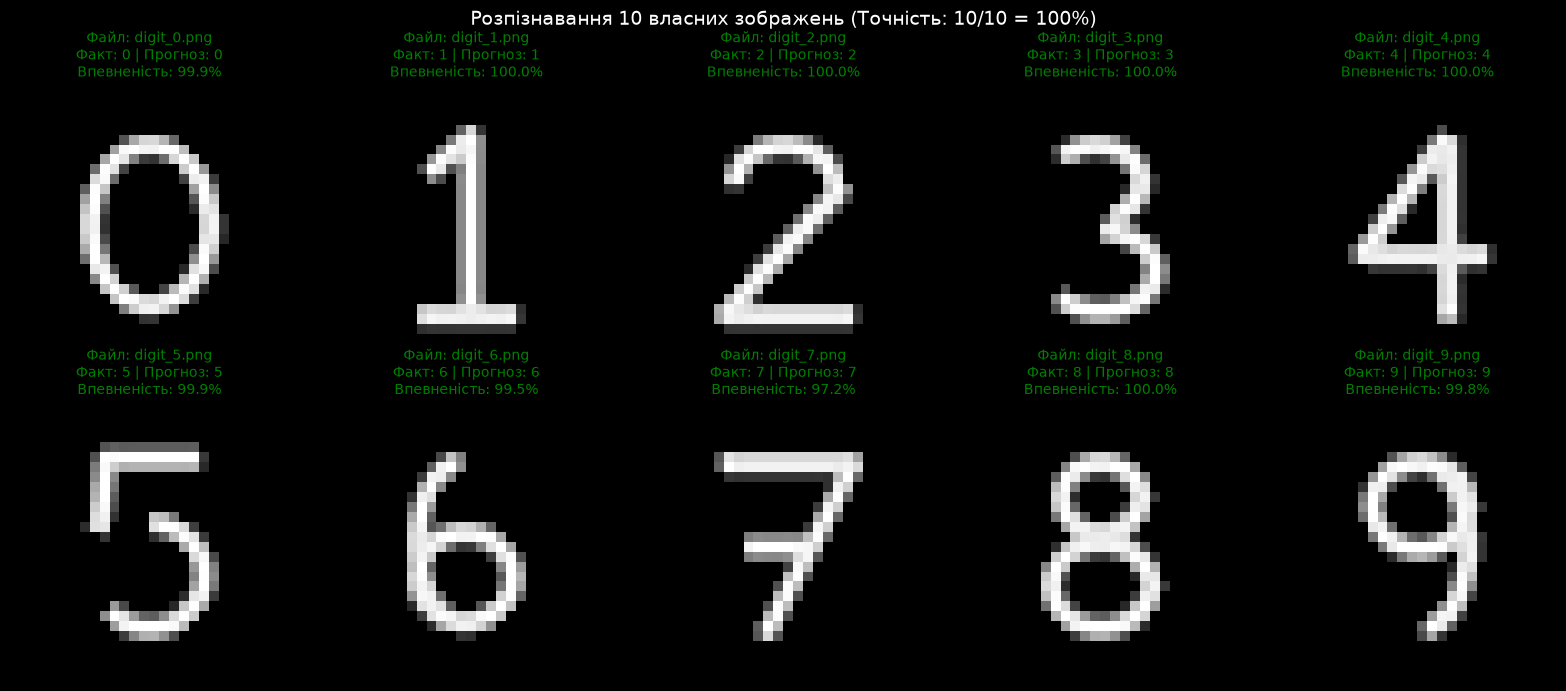

In [ ]:
custom_images_dir = 'my_digits'
custom_files = sorted([f for f in os.listdir(custom_images_dir) if f.startswith('digit_') and f.endswith('.png')])

plt.figure(figsize=(16, 7))
correct_count = 0

for i, filename in enumerate(custom_files):
    true_digit = int(filename.split('_')[1].split('.')[0])
    img_path = os.path.join(custom_images_dir, filename)
    
    orig_img, preprocessed_arr, tensor_input = preprocess_custom_image(img_path)
    
    pred_probs = loaded_model.predict(tensor_input, verbose=0)[0]
    pred_digit = np.argmax(pred_probs)
    conf = pred_probs[pred_digit] * 100
    
    if pred_digit == true_digit:
        correct_count += 1
        title_color = 'green'
    else:
        title_color = 'red'
        
    plt.subplot(2, 5, i + 1)
    plt.imshow(preprocessed_arr, cmap='gray')
    plt.title(f"Файл: {filename}\nФакт: {true_digit} | Прогноз: {pred_digit}\nВпевненість: {conf:.1f}%", 
              color=title_color, fontsize=10)
    plt.axis('off')

plt.suptitle(f"Розпізнавання 10 власних зображень (Точність: {correct_count}/10 = {correct_count*10}%)", fontsize=14)
plt.tight_layout()
plt.show()


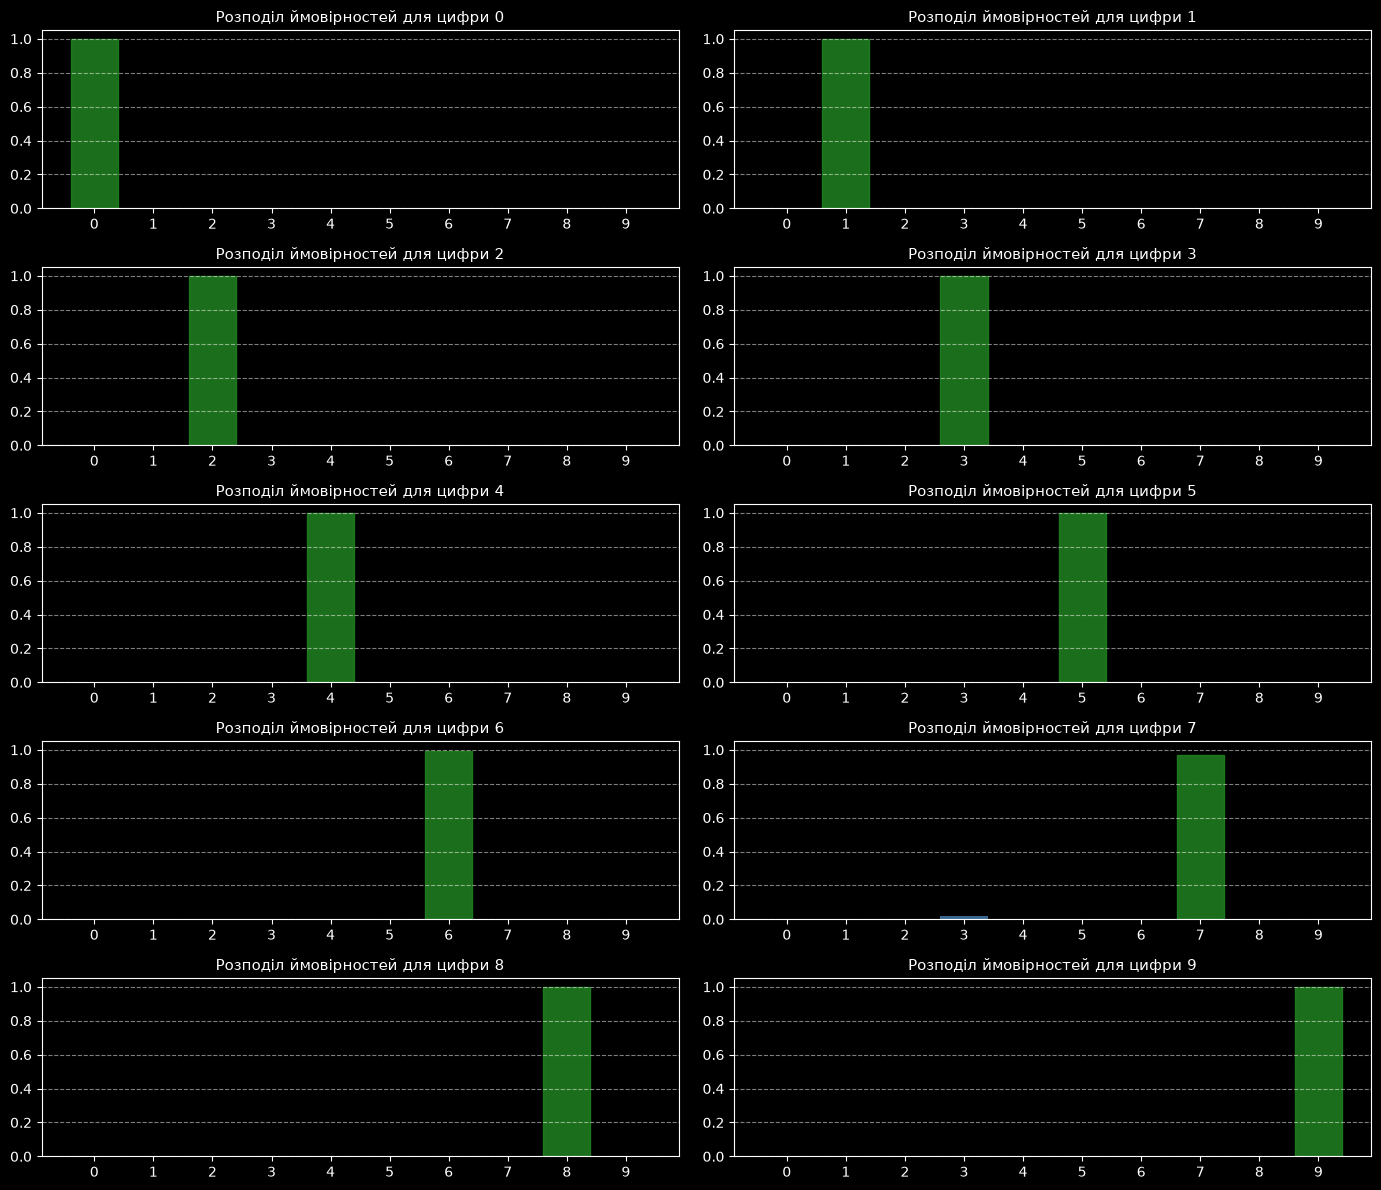

In [ ]:

fig, axes = plt.subplots(5, 2, figsize=(14, 12))
axes = axes.flatten()

for i, filename in enumerate(custom_files):
    true_digit = int(filename.split('_')[1].split('.')[0])
    img_path = os.path.join(custom_images_dir, filename)
    _, _, tensor_input = preprocess_custom_image(img_path)
    pred_probs = loaded_model.predict(tensor_input, verbose=0)[0]
    
    bars = axes[i].bar(range(10), pred_probs, color='steelblue', alpha=0.8)
    bars[true_digit].set_color('forestgreen')
    if np.argmax(pred_probs) != true_digit:
        bars[np.argmax(pred_probs)].set_color('crimson')
        
    axes[i].set_title(f"Розподіл ймовірностей для цифри {true_digit}", fontsize=11)
    axes[i].set_xticks(range(10))
    axes[i].set_ylim(0, 1.05)
    axes[i].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
comparison_data = {
    "Модель": [
        "Базовий MLP (1 прихований шар 784)", 
        "1-шарова CNN (Conv2D + MaxPool)", 
        "Simple CNN (Conv 32, Dropout 0.2)", 
        "Deeper CNN (Conv 30+15, Dense 128+50)", 
        "Improved CNN (BatchNorm + Dropout)"
    ],
    "Кількість параметрів": [
        model_mlp.count_params(),
        model_cnn1.count_params(),
        model_simple_cnn.count_params(),
        model_deeper_cnn.count_params(),
        model_improved.count_params()
    ],
    "Тестова точність (%)": [
        f"{mlp_accuracy:.2f}%",
        f"{scores_simple[1]*100:.2f}%",
        f"{scores_simple[1]*100:.2f}%",
        f"{scores_deeper[1]*100:.2f}%",
        f"{scores_improved[1]*100:.2f}%"
    ],
    "Помилка класифікації (%)": [
        f"{mlp_error:.2f}%",
        f"{100 - scores_simple[1]*100:.2f}%",
        f"{100 - scores_simple[1]*100:.2f}%",
        f"{100 - scores_deeper[1]*100:.2f}%",
        f"{100 - scores_improved[1]*100:.2f}%"
    ],
    "Цільове призначення": [
        "Базова лінія (Baseline)",
        "Швидка збіжність з Callback",
        "Проста згорткова топологія",
        "Багатошарова екстракція ознак",
        "Фінальна модель високої точності"
    ]
}

df_comparison = pd.DataFrame(comparison_data)
df_comparison


,Модель,Кількість параметрів,Тестова точність (%),Помилка класифікації (%),Цільове призначення
0,Базовий MLP (1 прихований шар 784),623290,97.93%,2.07%,Базова лінія (Baseline)
1,1-шарова CNN (Conv2D + MaxPool),693962,98.82%,1.18%,Швидка збіжність з Callback
2,"Simple CNN (Conv 32, Dropout 0.2)",592074,98.82%,1.18%,Проста згорткова топологія
3,"Deeper CNN (Conv 30+15, Dense 128+50)",59933,99.02%,0.98%,Багатошарова екстракція ознак
4,Improved CNN (BatchNorm + Dropout),422154,99.21%,0.79%,Фінальна модель високої точності
